<a href="https://colab.research.google.com/github/davidadewdney/Sudoku-Solver/blob/main/Sudoku_Solver.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Introduction



Sudoku is a very well known constraint satisfaction game consisting of a 9 x 9 grid that is to be filled with 1-9 digits repeatedly until the grid is full, while complying with its constraints. These constraints ensure that no number is repeated on the same row, column or within the same 3 x 3 grid. Although the rules are simple, manual solving becomes greatly inefficient with more complex puzzles. This complexity prevents brute-force approaches from being viable as they become very computationally expensive.

Due to its complexity, Sudoku provides a useful case study for AI and search-based problem solving techniques. Due to the unviability of simple search algorithms AI is commonly utilised to improve efficiency within sudoku solvers.

The aim of this project is to implement and compare 2 AI-based approaches for solving Sudoku puzzles: a basic backtracking search and an enhanced heuristic backtracking search incorporating the Minimum Remaining Values (MRV) heuristic  [find out more here](https://www.alooba.com/skills/concepts/data-science/minimum-remaining-values/). The backtracking search is used to provide a baseline approach to systematically explore values for each empty cell. The heuristic search builds upon this by selecting the cell with the fewest valid options at each step, reducing the branching factor of the search tree.

To evaluate and compare both methods, performance was measured through execution time and number of recursive calls required to solve each puzzle. These metrics were applied across a sample of a sudoku dataset to assess efficiency and scalability.

# Dataset

The dataset used to create the project consists of 1 million sudokus and their solutions. The puzzles and solutions are both formatted as strings of integers with varying levels of empty cells. These empty cells are represented with a 0. This dataset can be found here: [link to kaggle dataset by bryanpark](https://www.kaggle.com/datasets/bryanpark/sudoku)

In [ ]:
import kagglehub
import pandas as pd
import os

# Download the Sudoku dataset
s_path = kagglehub.dataset_download("bryanpark/sudoku")

print("Path to dataset files:", s_path)

# List files in dataset folder
os.listdir(s_path)

# Load CSV file
data = pd.read_csv(os.path.join(s_path, "sudoku.csv"))
#sampling 10000 puzzles from the million provided
sudoku = data.sample(n = 10000,random_state = 22)
sudoku.head()

100%|██████████| 68.1M/68.1M [00:00<00:00, 110MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/bryanpark/sudoku/versions/3


,quizzes,solutions
112004,1000900570006500022504000005430070160070060390...,1368924574786531922594718635439872168271465396...
780466,2080000064501030080375200000053007000600400928...,2189743564591632786375281499253817643617458928...
731928,0413708050300002007000960000200050008070406000...,6413728955394812767825961439236154878179436524...
914378,0004019008000724000106000200750001086030050072...,3274519868963724515146987239752631486438152972...
880256,0472600003001000050000374080000500900014080079...,8472651393291847656159374287843562912314986579...


Above the data is loaded into the project and sampled to a more reasonable size for use. This is due to the searches requiring a decent amount of time per sudoku. A sample of 10000 was decided due to its large size and therefore reflection of the population while also being computationally possible and not taking hours to complete.

In [ ]:
#beginning of dataset exploration
print("The dataset contains", len(sudoku["quizzes"]),"puzzles")
print("These puzzle have", len(sudoku["solutions"]), "solutions")
print("These puzzles have", len(sudoku["quizzes"].iloc[0]),"rows")
print("These puzzles have", len(sudoku["quizzes"].iloc[0][0]),"columns")
print("This means there is", len(sudoku["quizzes"])/len(sudoku["solutions"]),"quiz per solution")

The dataset contains 10000 puzzles
These puzzle have 10000 solutions
These puzzles have 81 rows
These puzzles have 1 columns
This means there is 1.0 quiz per solution


As can be seen here each puzzle has only 1 solution within the dataset. With each puzzle currently consisting of a row with a string of 81 integers all within 1 row. The sample we took successfully retained 10000 random puzzles.

# Preliminary Analysis

In [ ]:
#loading the first puzzle and solution
print(sudoku["quizzes"].iloc[0])
print(sudoku["solutions"].iloc[0])

100090057000650002250400000543007016007006039000200080000500901064010300700029008
136892457478653192259471863543987216827146539691235784382564971964718325715329648


As can be seen by the output from the first row of quizzes and solutions the dataset does not contain grids. Instead it contains a string of 81 numbers. This string is merely the sudoku numbers with 0 replacing the empty cells. This format is not suitable for solving a sudoku for various reasons. Firstly there are no rows, columns or 3 x 3 grids in which to uphold the constraints set by the rules of the game. This would mean any solver created upon this would have a very hard time simulating the rules of the game and therefore would be ineffective. Secondly with all the cells as one attached number there is no easy way to distinguish each number as a seperate entity providing extra challenge towards the solver. Therefore we would require a function to transform these strings of number sinto a grid to simulate sudoku.

In [ ]:
import numpy as np
#function to reshape the 81 integer string into a 9 x 9 array
def string_to_grid(puzzle):
  return np.array(list(puzzle),dtype = int).reshape((9,9))
sudoku["grid"] = sudoku["quizzes"].apply(string_to_grid)
print(sudoku["grid"].iloc[0])
sudoku["solgrid"] = sudoku["solutions"].apply(string_to_grid)
print(sudoku["solgrid"].iloc[0])

[[1 0 0 0 9 0 0 5 7]
 [0 0 0 6 5 0 0 0 2]
 [2 5 0 4 0 0 0 0 0]
 [5 4 3 0 0 7 0 1 6]
 [0 0 7 0 0 6 0 3 9]
 [0 0 0 2 0 0 0 8 0]
 [0 0 0 5 0 0 9 0 1]
 [0 6 4 0 1 0 3 0 0]
 [7 0 0 0 2 9 0 0 8]]
[[1 3 6 8 9 2 4 5 7]
 [4 7 8 6 5 3 1 9 2]
 [2 5 9 4 7 1 8 6 3]
 [5 4 3 9 8 7 2 1 6]
 [8 2 7 1 4 6 5 3 9]
 [6 9 1 2 3 5 7 8 4]
 [3 8 2 5 6 4 9 7 1]
 [9 6 4 7 1 8 3 2 5]
 [7 1 5 3 2 9 6 4 8]]


To tackle the problems stated above, the function above was written to convert the strings of 81 numbers into a 9 x 9 array to simulate the actual sudoku space. The first puzzle and solution is displayed to prove that the function has been effective and converted the string into a 9 x 9 grid. This will help to create a solver to meet the constraints set by the game of sudoku.

In [ ]:
print("These puzzles have", len(sudoku["grid"].iloc[0]),"rows")
print("These puzzles have", len(sudoku["grid"].iloc[0][0]),"columns")

These puzzles have 9 rows
These puzzles have 9 columns


Now as we can see these arrays count for rows and columns. Rather than having 81 rows and 1 column we now have 9 rows and 9 columns of numbers. This shows the effectiveness of the above function and will allow us to better analyse the grids by the sudoku constraints.

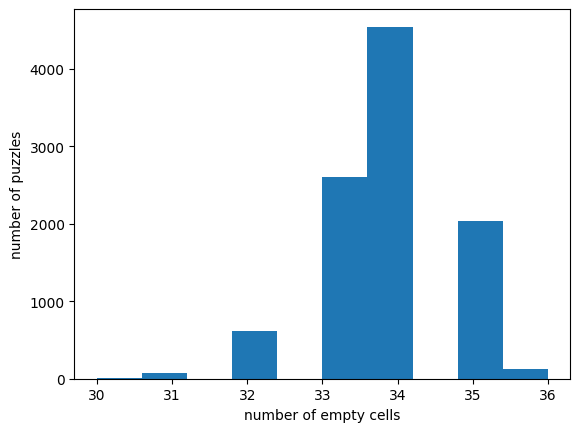

,quizzes,solutions,grid,solgrid
n_empty,,,,
30,6,6,6,6
31,77,77,77,77
32,618,618,618,618
33,2607,2607,2607,2607
34,4540,4540,4540,4540
35,2032,2032,2032,2032
36,120,120,120,120


In [ ]:
import matplotlib.pyplot as plt
# number of empty cells in each puzzle
sudoku["n_empty"] = sudoku["quizzes"].apply(lambda x: len(x.replace("0","")))
plt.hist(sudoku["n_empty"])
plt.ylabel("number of puzzles")
plt.xlabel("number of empty cells")
plt.show()
sudoku.groupby("n_empty").count()

As shown by the histogram and table majority of the sudokus within this dataset contain 34 empty cells. This would suggest they are at the most common level. There are a few below 33 which can be assumed as the easy difficulty and a few above 34 to be assumed as the hard difficulties. All sudokus range between 29 and 36 in sudoku counts within this sample. This reflects a relatively low spread within empty spaces throughout the dataset. We can also verify that no extra puzzles have been created within the data preprocessing which was needed to adapt the dataset to become viable.

# Methodology

Before we begin creating the heuristic model to solve sudokus we must make a basic model to compare against. To do this we will be using a baseline solver made by a backtracking search. Due to its simplicity and brute-force approach it creates a good basic approach in which to compare another model against. However before either model is constructed a function to check whether a number is viable within a space is required.

In [ ]:
#function to check if a number is valid in a cell from sudokus constraints
def valid(grid,row,col,num):
  if num in grid[row,:]:
    return False

  if num in grid[:,col]:
    return False

  start_row = 3*(row//3)
  start_col = 3*(col//3)

  if num in grid[start_row:start_row+3,start_col:start_col+3]:
    return False

  return True


Above a function is developed to check whether a cell is valid, whether a number already exists on that row or column, or whether it exists within its 3 x 3 grid already. Such are the rules of sudoku. This is accomplished within the 3 if statements. The first 2 check to see whether the number to input already exists within the same row or columns. With the 3rd if statement checking whether it is within the same 3 x 3 grid as the current coordinates. The starting row and column of the grid is found which is the top left of the mini grid, then a search is conducted within + 3 on the row and column to simulate the grid.

In [ ]:
#backtracking search solver
call_count = 0

def back_solver(grid):
  global call_count
  call_count = call_count + 1

  for i in range(9):
    for j in range(9):
      if grid[i,j] == 0:
        for num in range(1,10):
          if valid(grid,i,j,num):
            grid[i,j] = num

            if back_solver(grid):
              return True

            grid[i,j] = 0
        return False
  return True

The backtracking algorithm is created by the code above. This using previously created formula, checks whether, for each square on a sudoku grid, the square is a 0 and therefore needs replacing. Then which numbers are valid on it. Such that to be valid there has to be no numbers in its row, column or 3 x 3 grid that matches the inputted number. After then the formula calls itself again to continue solving the rest of the puzzle. If throughout the process there is no valid solution found with a certain cell it is then replaced back to 0 and tests other combinations of valid numbers. The process continues until a solution is found or all possibilities have been explored.

In [ ]:
#finding the cell with the least amount of choices
def Min_Rem_Val_empty(grid):
  min_choices = 10
  best_cell = None
  for i in range(9):
    for j in range(9):
      if grid[i,j] == 0:
        current_choices = 0
        for num_to_try in range(1,10):
          if valid(grid,i,j,num_to_try):
            current_choices = current_choices + 1

        if current_choices < min_choices:
          min_choices = current_choices
          best_cell = (i,j)
          if min_choices == 1:
              return best_cell
  return best_cell

Next the foundations for the heuristic search are laid out. This search will be very similiar to the backtracking search however it will start each recursion with the cell that has the least choices. This intuitively should reduce the number of recursions since there are less options, and since only one option is right, more chance of the correct number being chosen. In the code above this is created within the function which scans the entire 9 x 9 sudoku grid to identify all empty cells. For all empty cells the number of valid candidate values, according to sudokus constraints, are calculated. This is achieved by checking each number using the previously made valid function and counting how many satisfy the constraints for all empty cells.

In [ ]:
#creating heuristic solver
def heuristic_solver(grid):
  global call_count
  call_count = call_count + 1

  empty = Min_Rem_Val_empty(grid)
  if empty == None:
    return True
  else:
    i,j = empty
    for num in range(1,10):
      if valid(grid,i,j,num):
       grid[i,j] = num
       if heuristic_solver(grid):
         return True
       grid[i,j] = 0
  return False

Using the minimum remaining value calculator created before a backtracking solver is then created. This is accomplished by incorporating the minimum remaining value heuristic at all recursive steps. A global number of recursive calls is used here as with the backtracking search for ease of comparison. Once the empty cell with the least numerical options is discovered the backtracking search is then applied to find a solution. Once a successful solution is found within that cell it is continued until either all possibilities have been exhausted or a solution is found.

In [ ]:
#testing time measurement
import time
test_n = np.random.randint(0,10000)
check_t = sudoku["grid"].iloc[test_n].copy()
start_time = time.time()
back_solver(check_t)
end_time = time.time()
print("Time taken:",end_time-start_time)

Time taken: 0.006094932556152344


Here a methodology in which to time each puzzles solve was devised. The method is very simple with the time being taken at the beginning and end, with the difference then found. The difference provides an accurate depiction of how long the solver took to solve the puzzle. This will be an effective resource for comparison between the 2 methods.

In [ ]:
#applying backtracking search to the entire sample and measuring time and recursions
sudoku["recursions_b"] = 0
sudoku["time_b"] = 0.00
total_time = 0.00
total_start = time.time()
for index, puzzle in sudoku.iterrows():
  solution = sudoku["grid"].loc[index].copy()
  call_count = 0
  start_time = time.time()
  back_solver(solution)
  end_time = time.time()
  time_taken = end_time - start_time
  sudoku.at[index,"time_b"] = time_taken
  sudoku.at[index,"recursions_b"] = call_count
total_end = time.time()
total_time_b = total_end - total_start
print(total_time_b)

94.0366678237915


To complete the methodology, both searches were applied across the entire sample. This was computed with the total time taken per sudoku, total time to complete all 10000 and how many recursions were required all recorded. These will be used to compare each method. These are effective methods of measurement since recursions illustrates how efficient the algorithm is while time taken can show the computation required along with time being its own metric for success.

In [ ]:
#applying heuristic search to entire sample while recording recursions and time
sudoku["recursions_h"] = 0
sudoku["time_h"] = 0.00
total_time = 0.00
total_start = time.time()
for index, puzzle in sudoku.iterrows():
  solution = sudoku["grid"].loc[index].copy()
  call_count = 0
  start_time = time.time()
  heuristic_solver(solution)
  end_time = time.time()
  time_taken = end_time - start_time
  sudoku.at[index,"time_h"] = time_taken
  sudoku.at[index,"recursions_h"] = call_count
total_end = time.time()
total_time_h = total_end - total_start
print(total_time_h)

151.73325109481812


Now that the methodology is complete we can go onto spotting any trends and patterns to properly compare the 2 searches.

# Results

To quickly test whether both methods worked, a test was conducted on a random puzzle within the dataset. The searches were then applied onto the incomplete puzzle and tested against the given solution. As can be seen both successfully accomplished the correct solution.

In [ ]:
test_n = np.random.randint(0,10000)
check_b = sudoku["grid"].iloc[test_n].copy()
back_solver(check_b)
print(check_b)
check_b == sudoku["solgrid"].iloc[test_n]


[[7 6 9 2 3 4 1 8 5]
 [5 2 8 1 7 6 3 4 9]
 [1 3 4 5 9 8 2 6 7]
 [4 7 6 3 1 9 5 2 8]
 [9 5 2 6 8 7 4 1 3]
 [8 1 3 4 5 2 9 7 6]
 [2 4 7 9 6 3 8 5 1]
 [6 9 1 8 4 5 7 3 2]
 [3 8 5 7 2 1 6 9 4]]


array([[ True,  True,  True,  True,  True,  True,  True,  True,  True],
       [ True,  True,  True,  True,  True,  True,  True,  True,  True],
       [ True,  True,  True,  True,  True,  True,  True,  True,  True],
       [ True,  True,  True,  True,  True,  True,  True,  True,  True],
       [ True,  True,  True,  True,  True,  True,  True,  True,  True],
       [ True,  True,  True,  True,  True,  True,  True,  True,  True],
       [ True,  True,  True,  True,  True,  True,  True,  True,  True],
       [ True,  True,  True,  True,  True,  True,  True,  True,  True],
       [ True,  True,  True,  True,  True,  True,  True,  True,  True]])

In [ ]:
check_h = sudoku["grid"].iloc[test_n].copy()
heuristic_solver(check_h)
print(check_h)
check_h == sudoku["solgrid"].iloc[test_n]

[[7 6 9 2 3 4 1 8 5]
 [5 2 8 1 7 6 3 4 9]
 [1 3 4 5 9 8 2 6 7]
 [4 7 6 3 1 9 5 2 8]
 [9 5 2 6 8 7 4 1 3]
 [8 1 3 4 5 2 9 7 6]
 [2 4 7 9 6 3 8 5 1]
 [6 9 1 8 4 5 7 3 2]
 [3 8 5 7 2 1 6 9 4]]


array([[ True,  True,  True,  True,  True,  True,  True,  True,  True],
       [ True,  True,  True,  True,  True,  True,  True,  True,  True],
       [ True,  True,  True,  True,  True,  True,  True,  True,  True],
       [ True,  True,  True,  True,  True,  True,  True,  True,  True],
       [ True,  True,  True,  True,  True,  True,  True,  True,  True],
       [ True,  True,  True,  True,  True,  True,  True,  True,  True],
       [ True,  True,  True,  True,  True,  True,  True,  True,  True],
       [ True,  True,  True,  True,  True,  True,  True,  True,  True],
       [ True,  True,  True,  True,  True,  True,  True,  True,  True]])

In [ ]:
print("Total time taken for the backtracking search to solve all sudokus within the sample was",total_time_b, "seconds")
print("Total time taken for the heuristic search to solve all sudokus within the sample",total_time_h,"seconds")

Total time taken for the backtracking search to solve all sudokus within the sample was 94.0366678237915 seconds
Total time taken for the heuristic search to solve all sudokus within the sample 151.73325109481812 seconds


The results from the total times show that despite being more efficient the heuristic search took significantly longer with 30 seconds more than the backtracking search. This is due to the heuristic algorithm having a more computationally expensive process to find which cell to act upon.

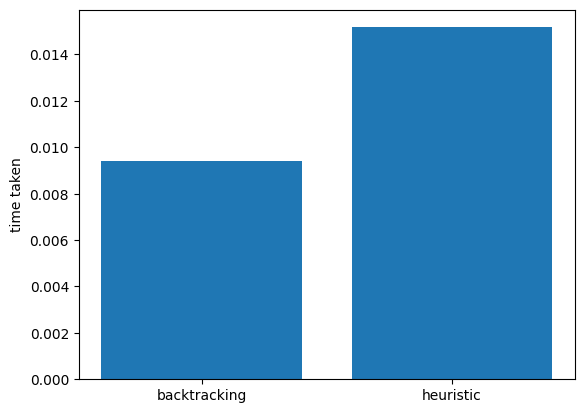

In [ ]:
t_avg_h = total_time_h/10000
t_avg_b = total_time_b/10000
plt.bar(["backtracking","heuristic"],[t_avg_b,t_avg_h])
plt.ylabel("time taken")
plt.show()

The bar chart above shows us that the heuristic search took 0.006 seconds longer than the backtracking search on average. Which is a 67% increase within time.

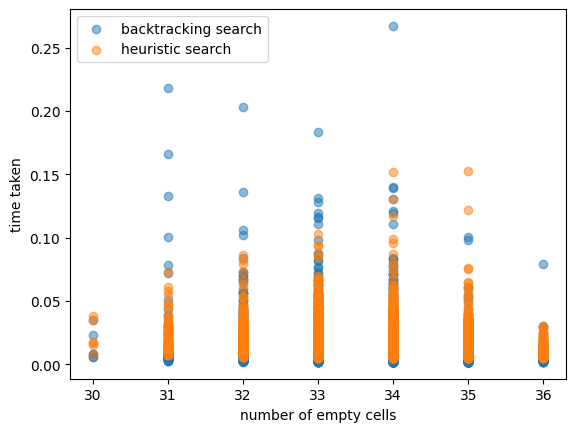

In [ ]:
plt.figure()
plt.scatter(sudoku["n_empty"],sudoku["time_b"],label = "backtracking search",alpha = 0.5)
plt.scatter(sudoku["n_empty"],sudoku["time_h"],label = "heuristic search",alpha = 0.5)
plt.xlabel("number of empty cells")
plt.ylabel("time taken")
plt.legend()
plt.show()

To further analyse the bar chart a scatter plot has been constructed to show the time taken by each approach. The blue represents the backtracking search and the orange represents the heuristic search. Despite backtracking search having the lower average time as we can see here it contains the majority of solves which took an above average amount of time. This is likely due to the random nature of the search. The heuristic search while taking longer on average provides a more reliable time in which a solution will be found.

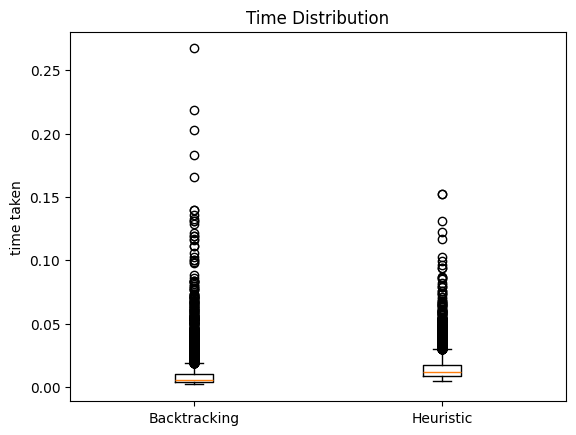

In [ ]:
plt.figure()
plt.boxplot([sudoku["time_b"],sudoku["time_h"]],tick_labels = ["Backtracking","Heuristic"])
plt.title("Time Distribution")
plt.ylabel("time taken")
plt.show()

This is further backed up by the box plots of the time distribution. As can be seen heuristic contains much less so ready within its outliers while backtracking has a far spread. These distributions of time within the searches show us that heuristic also contains a larger inter quartile range.

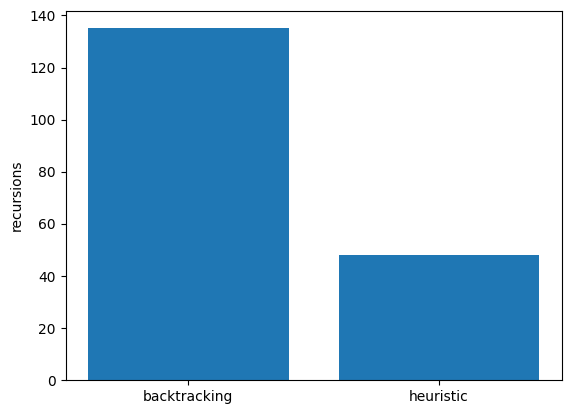

In [ ]:
r_avg_h = sudoku["recursions_h"].mean()
r_avg_b = sudoku["recursions_b"].mean()
plt.bar(["backtracking","heuristic"],[r_avg_b,r_avg_h])
plt.ylabel("recursions")
plt.show()

The bar chart shows us that while taking a higher amount of time on average to solve the heuristic search takes far fewer recursions. This was the expected result due to the heuristic search deciding on its starting cell based on a higher probability of success. This intuitive decision allows it to have less than half of the recursions on average than the backtracking method. This is a 74% decrease in recursions.

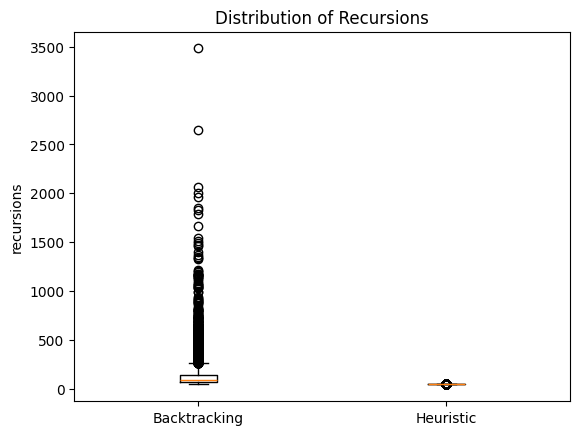

In [ ]:
plt.figure()
plt.boxplot([sudoku["recursions_b"],sudoku["recursions_h"]],tick_labels = ["Backtracking","Heuristic"])
plt.title("Distribution of Recursions")
plt.ylabel("recursions")
plt.show()

The boxpot used above illustrates the significant difference in distribution of recursions between the 2 searches. With heuristic search containing a very small range and very few outliers, while backtracking ranges all the way up to 3500. This shows the difference in efficiency between the 2 methods. With heuristic being far more efficient compared to the backtracking search. Heuristic search also has a significantly smaller inter quartile range informing us that the spread of the data is just very small.

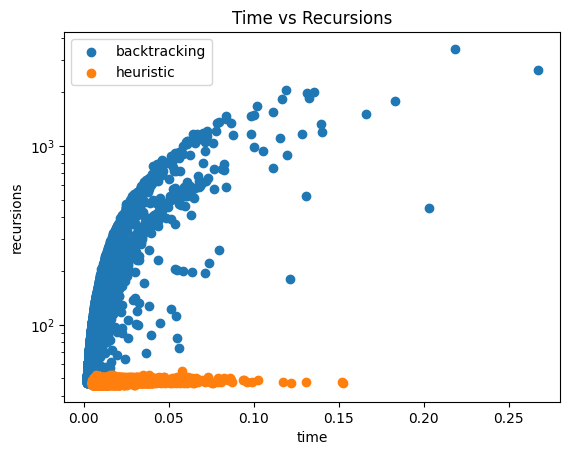

In [ ]:
plt.figure()
plt.scatter(sudoku["time_b"],sudoku["recursions_b"],label = "backtracking")
plt.scatter(sudoku["time_h"],sudoku["recursions_h"],label = "heuristic")
plt.yscale("log")
plt.title("Time vs Recursions")
plt.xlabel("time")
plt.ylabel("recursions")
plt.legend()
plt.show()

This graph illustrates a very interesting pattern between the recursions and time of both methods. While backtracking search contains a clear positive trend heuristic search contains a low correlation between its time and recursions. This lack of correlation shows us that the heuristic algorithm has worked effectively. The efficiency displayed show that even during the harder sudokus with a longer time the heuristic search will still perform very efficiently whereas the backtracking search will take a considerable amount of time and recursions.

# Conclusion

This project implemented and evaluated 2 approaches for solving sudoku puzzles, these were a backtracking search and a heuristic search. Both methods were able to correctly solve all 10000 puzzles within the sample correctly, however their efficiency and time differed significantly.

The results showed us that the backtracking approach was on average quicker however had a much larger spread and was more inconsistent. This led to the observation that the heuristic algorithm performed better, since it was more consistent within its timeframe with less outliers. Despite having a higher average majority of the heuristically solved times were very near the mean for both whereas the same cannot be said for backtracking search.

In terms of recursive calls, heuristic dominated having far less on average and as shown by the box plot a significantly lower spread. This shows the efficiency and effectiveness provided from a heuristic choice of starting cell.

Overall the findings demonstrate that incorporating heuristic strategies into backtracking searches significantly improves search efficiency and reduces the randomness. This efficiency would be extra visible on harder puzzles, where there are often more empty cells, while the backtracking due to its simpler nature would be more effective with very easy low empty cell puzzles.